# Optimisation

5 plis pour valider et 3 plis internes pour regler les parametres. Choisir le modele avant le test. Projet pedagogique, sans usage clinique.

## 1. Donnees

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.optimize import optimize_model, cross_validate_model
from src.evaluate import evaluate_model

folder = PROJECT_ROOT / "metrique"
folder.mkdir(exist_ok=True)
models_folder = PROJECT_ROOT / "models"
models_folder.mkdir(exist_ok=True)

df = pd.read_csv(PROJECT_ROOT / "data/raw/student_mental_health.csv")
df = df.drop_duplicates().dropna(subset=["Mental_Health_Risk"])
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]
X_train, X_test, y_train_text, y_test_text = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train_text)
class_names = encoder.classes_
assert set(X_train.index).isdisjoint(X_test.index)
print("Train :", len(X_train), "- Test reserve :", len(X_test))


Train : 1600 - Test reserve : 400


## 2. Parametres a essayer

GridSearchCV choisit le meilleur F1 macro.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, 
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42, 
        n_jobs=2
    ),
    "XGBoost": XGBClassifier(
        learning_rate=0.05, 
        subsample=0.8, 
        colsample_bytree=0.8,
        objective="multi:softprob", 
        eval_metric="mlogloss",
        tree_method="hist", 
        random_state=42, 
        n_jobs=2,
    ),
}
parameters = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
        },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, None],
        "model__min_samples_leaf": [2],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3],
    },
}
validation = {}


## 3. Validation croisee

Chaque ligne est predite par un modele qui ne l a pas vue. Le preprocessing est appris dans les plis.

In [3]:
name = "Logistic Regression"
print(name, flush=True)
validation[name] = cross_validate_model(
    models[name], parameters[name], X_train, y_train, class_names
)


Logistic Regression
Pli 1 termine
Pli 2 termine
Pli 3 termine
Pli 4 termine
Pli 5 termine


In [4]:
name = "Random Forest"
print(name, flush=True)
validation[name] = cross_validate_model(
    models[name], parameters[name], X_train, y_train, class_names
)


Random Forest
Pli 1 termine
Pli 2 termine
Pli 3 termine
Pli 4 termine
Pli 5 termine


In [5]:
name = "XGBoost"
print(name, flush=True)
validation[name] = cross_validate_model(
    models[name], parameters[name], X_train, y_train, class_names
)


XGBoost
Pli 1 termine
Pli 2 termine
Pli 3 termine
Pli 4 termine
Pli 5 termine


## 4. Choix sur validation

Enregistrer les scores de chaque pli.

In [11]:
validation_rows = []
fold_tables = []
for name, result in validation.items():
    validation_rows.append({"Modele": name, **result["evaluation"]["metrics"]})
    fold_tables.append(result["folds"].assign(Modele=name))

validation_scores = pd.DataFrame(validation_rows).set_index("Modele")
selected_name = validation_scores["F1 macro"].idxmax()
fold_scores = pd.concat(fold_tables, ignore_index=True)
fold_scores.to_csv(folder / "cv_fold_metrics.csv", index=False)
display(validation_scores.round(4))
print("Modele retenu sur validation :", selected_name)


,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
Modele,,,,,
Logistic Regression,0.7519,0.7499,0.7512,0.7505,0.9023
XGBoost,0.7006,0.6972,0.6998,0.6983,0.8656
Random Forest,0.6775,0.6703,0.6765,0.6725,0.8559


Accuracy         F1 macro        
                        mean     std     mean     std
Modele                                               
Logistic Regression   0.7519  0.0233   0.7503  0.0239
Random Forest         0.6775  0.0205   0.6723  0.0194
XGBoost               0.7006  0.0318   0.6983  0.0297

Modele retenu avant le test : Logistic Regression


## 5. Entrainement final

Optimiser sur tout le train, puis sauvegarder les pipelines dans models.

In [ ]:
optimized_models = {}
for name, model in models.items():
    search = optimize_model(model, parameters[name], X_train, y_train)
    optimized_models[name] = search.best_estimator_
    bundle = {"pipeline": search.best_estimator_, "label_encoder": encoder,
              "class_names": class_names, "training_rows": len(X_train),
              "best_parameters": search.best_params_}
    slug = name.lower().replace(" ", "_")
    joblib.dump(bundle, models_folder / ("optimized_" + slug + ".joblib"))
    if name == selected_name:
        joblib.dump(bundle, models_folder / "selected_model.joblib")
    print(name, search.best_params_)


## 6. Metriques finales

Train : score apparent. Validation : predictions hors pli. Test : score final, sans nouveau reglage.

In [13]:
y_test = encoder.transform(y_test_text)
rows = []
results = {}
for name, model in optimized_models.items():
    results[name] = {
        "Train": evaluate_model(model, X_train, y_train, class_names),
        "Validation CV": validation[name]["evaluation"],
        "Test": evaluate_model(model, X_test, y_test, class_names),
    }
    for split, result in results[name].items():
        rows.append({"Modele": name, "Ensemble": split, **result["metrics"]})

metrics = pd.DataFrame(rows)
metrics.to_csv(folder / "validation_test_metrics.csv", index=False)
display(metrics.round(4))


,Modele,Ensemble,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
0,Logistic Regression,Train,0.7669,0.7670,0.7664,0.7667,0.9147
1,Logistic Regression,Validation CV,0.7519,0.7499,0.7512,0.7505,0.9023
2,Logistic Regression,Test,0.7525,0.7510,0.7518,0.7514,0.9141
3,Random Forest,Train,0.9994,0.9994,0.9994,0.9994,1.0000
4,Random Forest,Validation CV,0.6775,0.6703,0.6765,0.6725,0.8559
5,Random Forest,Test,0.7275,0.7239,0.7268,0.7250,0.8685
6,XGBoost,Train,0.8725,0.8714,0.8721,0.8716,0.9693
7,XGBoost,Validation CV,0.7006,0.6972,0.6998,0.6983,0.8656
8,XGBoost,Test,0.7250,0.7223,0.7245,0.7233,0.8834


## 7. Accuracy

Les lignes montrent les plis, pas des epoques. Le test est un point final.

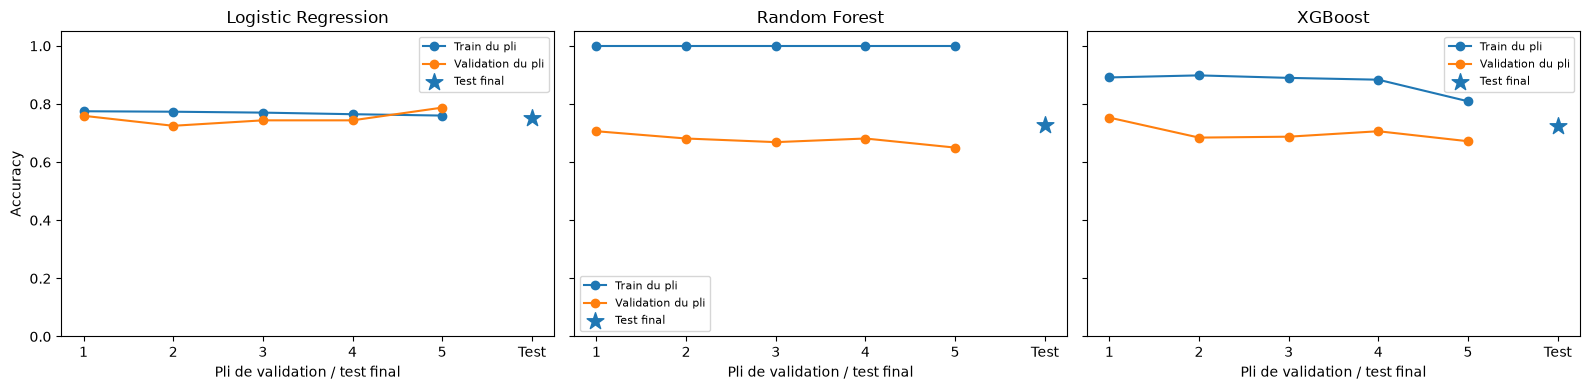

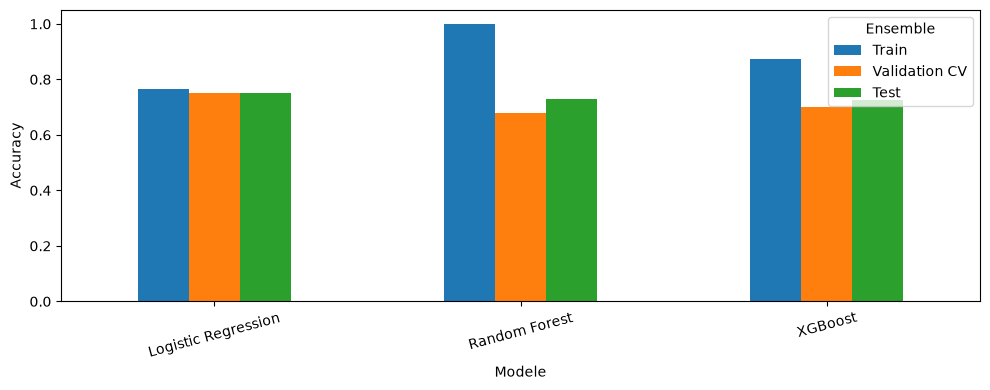

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, models):
    scores = fold_scores[fold_scores["Modele"] == name]
    ax.plot(scores["Fold"], scores["Accuracy train"], "o-", label="Train du pli")
    ax.plot(scores["Fold"], scores["Accuracy"], "o-", label="Validation du pli")
    ax.scatter([6], [results[name]["Test"]["metrics"]["Accuracy"]], marker="*", s=160, label="Test final")
    ax.set_xticks([1, 2, 3, 4, 5, 6], ["1", "2", "3", "4", "5", "Test"])
    ax.set_ylim(0, 1.05)
    ax.set_title(name)
    ax.set_xlabel("Pli de validation / test final")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Accuracy")
plt.tight_layout()
plt.savefig(folder / "accuracy_cv.png", dpi=160)
plt.show()

accuracy = metrics.pivot(index="Modele", columns="Ensemble", values="Accuracy")
accuracy = accuracy[["Train", "Validation CV", "Test"]]
accuracy.plot(kind="bar", figsize=(10, 4), ylim=(0, 1.05))
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(folder / "accuracy_train_validation_test.png", dpi=160)
plt.show()


Le test a deja ete consulte lors de l execution precedente. Les scores conserves sont historiques ; ne pas regler les modeles a partir du test. Les essais de regularisation restent dans le notebook 04.